In [1]:
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
imports = pd.read_csv(r"C:\Users\racol\OneDrive\Desktop\coffee-yen-project\data\raw\japan_green_coffee_imports_2010_2026.csv")
imports.head()

,month,quantity_kg,value_thousand_yen,value_yen,yen_per_kg
0,2010-01,28031253,7217477,7217477000,257.5
1,2010-02,28358072,7224624,7224624000,254.8
2,2010-03,38966837,10448859,10448859000,268.1
3,2010-04,38096203,11229699,11229699000,294.8
4,2010-05,38514372,10952713,10952713000,284.4


In [3]:
# Folder where all the raw data files are saved
DATA = r"C:\Users\racol\OneDrive\Desktop\coffee-yen-project\data\raw"

In [4]:
# ---------- Arabica ----------

# Source: IMF (International Money Fund) via FRED, series PCOFFOTMUSDM, U.S. cents per pound, monthly
arabica = pd.read_csv(DATA + r"\arabica_price.csv")

# Convert dates to real dates and give columns clear names
arabica["observation_date"] = pd.to_datetime(arabica["observation_date"])
arabica = arabica.rename(columns={
    "observation_date": "month",
    "PCOFFOTMUSDM": "arabica_cents_lb"
})

# Health check: size, missing values, date range
print("ARABICA")
print("Shape:", arabica.shape)
print("Missing values:", arabica.isna().sum().sum())
print("Dates:", arabica["month"].min().date(), "to", arabica["month"].max().date())
print()

ARABICA
Shape: (193, 2)
Missing values: 0
Dates: 2010-07-01 to 2026-07-01



In [5]:
# ---------- Robusta ----------
# Source: IMF via FRED (Federal Reserve Economic Data), series PCOFFROBUSDM, U.S. cents per pound, monthly
robusta = pd.read_csv(DATA + r"\robusta_price.csv")

# Convert dates to real dates and give columns clear names
robusta["observation_date"] = pd.to_datetime(robusta["observation_date"])
robusta = robusta.rename(columns={
    "observation_date": "month",
    "PCOFFROBUSDM": "robusta_cents_lb"
})

# Health check: size, missing values, date range
print("ROBUSTA")
print("Shape:", robusta.shape)
print("Missing values:", robusta.isna().sum().sum()) 
print("Dates:", robusta["month"].min().date(), "to", robusta["month"].max().date())
print()



ROBUSTA
Shape: (199, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-07-01



In [6]:
arabica.head()

,month,arabica_cents_lb
0,2010-07-01,203.213636
1,2010-08-01,211.590000
2,2010-09-01,222.713182
3,2010-10-01,217.439048
4,2010-11-01,233.512727


In [7]:
# ---------- Yen per U.S. dollar ----------

# Source: Federal Reserve Board via FRED, series EXJPUS, monthly average
yen = pd.read_csv(DATA + r"\yendollar_rate.csv")

# Convert dates to real dates and give columns clear names
yen["observation_date"] = pd.to_datetime(yen["observation_date"])
yen = yen.rename(columns={
    "observation_date": "month",
    "EXJPUS": "yen_per_usd"
})

# Health check: size, missing values, date range
print("YEN PER DOLLAR")
print("Shape:", yen.shape)
print("Missing values:", yen.isna().sum().sum())
print("Dates:", yen["month"].min().date(), "to", yen["month"].max().date())

YEN PER DOLLAR
Shape: (201, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-09-01


In [8]:
yen.head()

,month,yen_per_usd
0,2010-01-01,91.1011
1,2010-02-01,90.1395
2,2010-03-01,90.7161
3,2010-04-01,93.4527
4,2010-05-01,91.9730


In [9]:
# Merge the three tables on the "month" column
fred = (arabica
        .merge(robusta, on="month", how="outer")
        .merge(yen, on="month", how="outer"))

# Keep January 2010 onward and put the months in order
fred = fred[fred["month"] >= "2010-01-01"].sort_values("month").reset_index(drop=True)

# Check the merged table
print("Shape:", fred.shape)
print()
print("Missing values per column:")
print(fred.isna().sum())

# Show which months have gaps, so we know exactly where they are
fred[fred.isna().any(axis=1)]

Shape: (201, 4)

Missing values per column:
month               0
arabica_cents_lb    8
robusta_cents_lb    2
yen_per_usd         0
dtype: int64


,month,arabica_cents_lb,robusta_cents_lb,yen_per_usd
0,2010-01-01,NaN,69.939524,91.1011
1,2010-02-01,NaN,67.884500,90.1395
2,2010-03-01,NaN,67.247391,90.7161
3,2010-04-01,NaN,71.636364,93.4527
4,2010-05-01,NaN,70.723810,91.9730
5,2010-06-01,NaN,76.921818,90.8059
199,2026-08-01,NaN,NaN,158.8476
200,2026-09-01,NaN,NaN,156.4171


In [10]:
fred.head(20)

,month,arabica_cents_lb,robusta_cents_lb,yen_per_usd
0,2010-01-01,NaN,69.939524,91.1011
1,2010-02-01,NaN,67.884500,90.1395
2,2010-03-01,NaN,67.247391,90.7161
3,2010-04-01,NaN,71.636364,93.4527
4,2010-05-01,NaN,70.723810,91.9730
5,2010-06-01,NaN,76.921818,90.8059
6,2010-07-01,203.213636,85.273182,87.5005
7,2010-08-01,211.590000,82.696364,85.3727
8,2010-09-01,222.713182,81.278182,84.3571
9,2010-10-01,217.439048,85.119524,81.7285


In [11]:
# Number of pounds in one kilogram
LB_PER_KG = 2.20462

# Step 1 and 2: U.S. cents per pound -> U.S. dollars per kg
fred["arabica_usd_kg"] = fred["arabica_cents_lb"] / 100 * LB_PER_KG
fred["robusta_usd_kg"] = fred["robusta_cents_lb"] / 100 * LB_PER_KG

# Step 3: U.S. dollars per kg -> yen per kg, using each month's exchange rate
fred["arabica_yen_kg"] = fred["arabica_usd_kg"] * fred["yen_per_usd"]
fred["robusta_yen_kg"] = fred["robusta_usd_kg"] * fred["yen_per_usd"]

# Sanity check: compare one early month and one recent month
check_months = pd.to_datetime(["2015-01-01", "2025-01-01"])
fred[fred["month"].isin(check_months)].round(1)

,month,arabica_cents_lb,robusta_cents_lb,yen_per_usd,arabica_usd_kg,robusta_usd_kg,arabica_yen_kg,robusta_yen_kg
60,2015-01-01,189.6,97.9,118.2,4.2,2.2,494.3,255.2
180,2025-01-01,353.9,244.9,156.5,7.8,5.4,1221.0,845.0


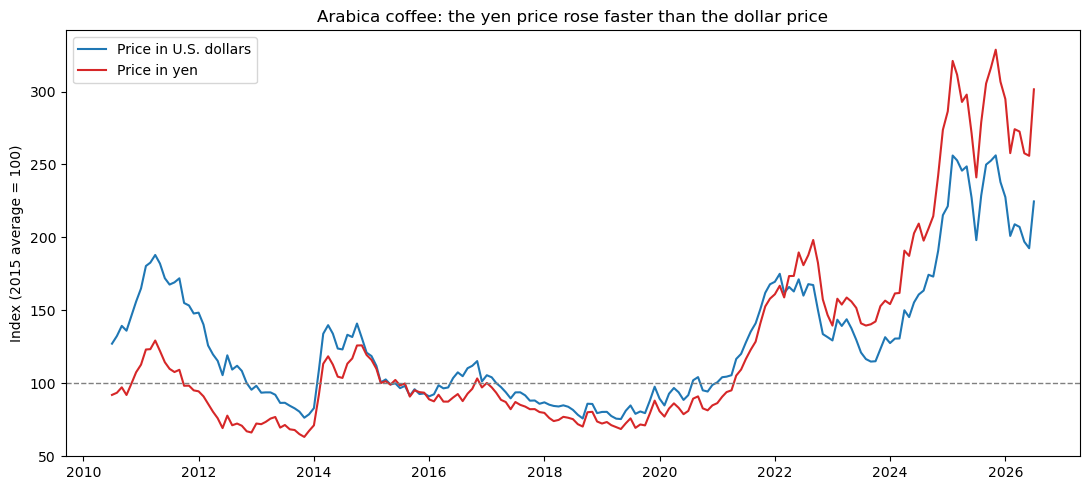

In [12]:
# Use the 2015 average as the baseline (2015 = 100)
base = fred[fred["month"].dt.year == 2015]

# Index each series and put on the same scale
fred["arabica_usd_index"] = fred["arabica_usd_kg"] / base["arabica_usd_kg"].mean() * 100
fred["arabica_yen_index"] = fred["arabica_yen_kg"] / base["arabica_yen_kg"].mean() * 100

# Plot both lines on the same scale
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(fred["month"], fred["arabica_usd_index"], label="Price in U.S. dollars", color="tab:blue")
ax.plot(fred["month"], fred["arabica_yen_index"], label="Price in yen", color="tab:red")

# Reference line at 100 (the 2015 level)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)

# Labels and title
ax.set_title("Arabica coffee: the yen price rose faster than the dollar price")
ax.set_ylabel("Index (2015 average = 100)")
ax.legend()
plt.tight_layout()
plt.show()

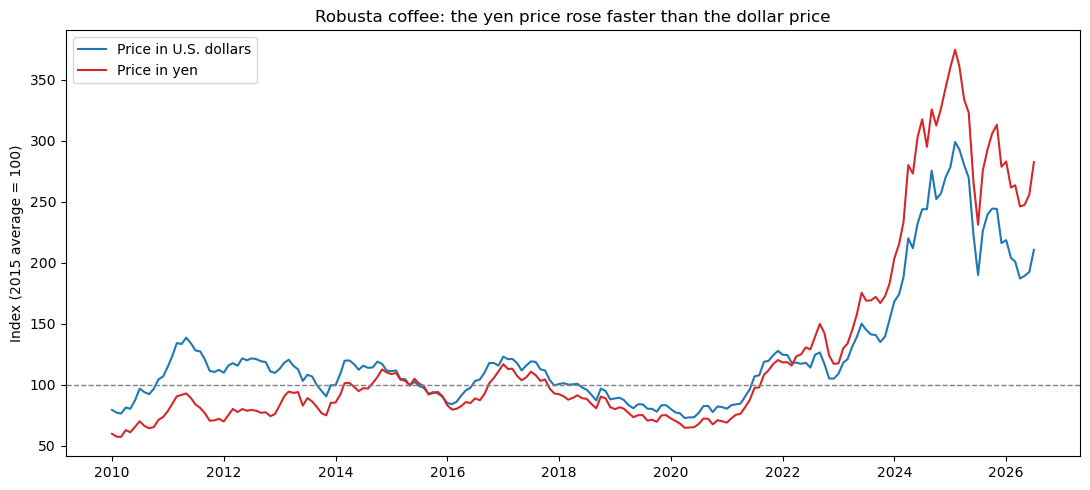

In [13]:
# Use the 2015 average as the baseline (2015 = 100)
base = fred[fred["month"].dt.year == 2015]

# Index each series and put on the same scale
fred["robusta_usd_index"] = fred["robusta_usd_kg"] / base["robusta_usd_kg"].mean() * 100
fred["robusta_yen_index"] = fred["robusta_yen_kg"] / base["robusta_yen_kg"].mean() * 100

# Plot both lines on the same scale
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(fred["month"], fred["robusta_usd_index"], label="Price in U.S. dollars", color="tab:blue")
ax.plot(fred["month"], fred["robusta_yen_index"], label="Price in yen", color="tab:red")

# Reference line at 100 (the 2015 level)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)

# Labels and title
ax.set_title("Robusta coffee: the yen price rose faster than the dollar price")
ax.set_ylabel("Index (2015 average = 100)")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# ---------- Japan green coffee imports ----------

# Source: Japan Customs, Trade Statistics of Japan, HS 0901.11, monthly total
# yen_per_kg = value paid (including shipping and insurance) / quantity
imports = pd.read_csv(DATA + r"\japan_green_coffee_imports_2010_2026.csv")

# Convert "2010-01" text into real dates (first day of each month, matching the FRED table)
imports["month"] = pd.to_datetime(imports["month"])

# Keep only the columns we need 
imports = imports[["month", "quantity_kg", "yen_per_kg"]].rename(
    columns={"yen_per_kg": "import_yen_kg"}
)


print("IMPORTS")
print("Shape:", imports.shape)
print("Missing values:", imports.isna().sum().sum())
print("Dates:", imports["month"].min().date(), "to", imports["month"].max().date())

imports.head()

IMPORTS
Shape: (200, 3)
Missing values: 0
Dates: 2010-01-01 to 2026-08-01


,month,quantity_kg,import_yen_kg
0,2010-01-01,28031253,257.5
1,2010-02-01,28358072,254.8
2,2010-03-01,38966837,268.1
3,2010-04-01,38096203,294.8
4,2010-05-01,38514372,284.4


In [15]:
# Add Japan's actual import cost to the FRED table, matched by month
# how="outer" keeps every month from both tables, so any gaps stay visible
combined = fred.merge(imports, on="month", how="outer").sort_values("month").reset_index(drop=True)

# Health check: which columns have gaps after the merge?
print("Shape:", combined.shape)
print(combined[["arabica_yen_kg", "robusta_yen_kg", "import_yen_kg"]].isna().sum())

Shape: (201, 14)
arabica_yen_kg    8
robusta_yen_kg    2
import_yen_kg     1
dtype: int64


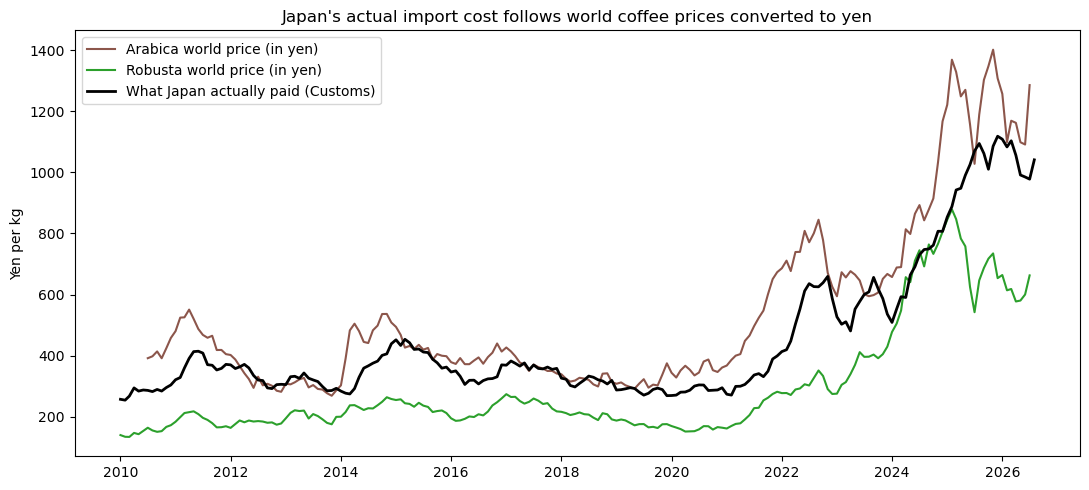

In [16]:
# Chart: world prices in yen vs. what Japan actually paid, all in yen per kg
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(combined["month"], combined["arabica_yen_kg"], label="Arabica world price (in yen)", color="tab:brown")
ax.plot(combined["month"], combined["robusta_yen_kg"], label="Robusta world price (in yen)", color="tab:green")
ax.plot(combined["month"], combined["import_yen_kg"], label="What Japan actually paid (Customs)", color="black", linewidth=2)

# Labels and title
ax.set_title("Japan's actual import cost follows world coffee prices converted to yen")
ax.set_ylabel("Yen per kg")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
combined["year"] = combined["month"].dt.year

# Average import cost (yen per kg) and exchange rate (yen per dollar) for each year
yearly = combined.groupby("year")[["import_yen_kg", "yen_per_usd"]].mean()

# Keep 2015 onward, since 2015 is our baseline
yearly = yearly.loc[2015:]

yearly.round(1)

,import_yen_kg,yen_per_usd
year,,
2015,411.3,121.0
2016,329.5,108.8
2017,365.5,112.1
2018,317.5,110.4
2019,285.8,109.0
2020,288.1,106.8
2021,326.7,109.8
2022,560.3,131.5
2023,563.4,140.5


In [18]:
# Japan's import cost in U.S. dollars per kg (yen price / exchange rate)
yearly["import_usd_kg"] = yearly["import_yen_kg"] / yearly["yen_per_usd"]

# Baseline values from 2015
base_yen_price = yearly.loc[2015, "import_yen_kg"]
base_fx = yearly.loc[2015, "yen_per_usd"]

# "What if" price: this year's dollar price, but converted at the 2015 exchange rate
yearly["whatif_yen_kg"] = yearly["import_usd_kg"] * base_fx

# Split the change since 2015 into two parts (in yen per kg)
yearly["coffee_market_effect"] = yearly["whatif_yen_kg"] - base_yen_price
yearly["weak_yen_effect"] = yearly["import_yen_kg"] - yearly["whatif_yen_kg"]

yearly[["import_yen_kg", "whatif_yen_kg", "coffee_market_effect", "weak_yen_effect"]].round(0)

,import_yen_kg,whatif_yen_kg,coffee_market_effect,weak_yen_effect
year,,,,
2015,411.0,411.0,0.0,0.0
2016,329.0,367.0,-45.0,-37.0
2017,366.0,394.0,-17.0,-29.0
2018,317.0,348.0,-63.0,-30.0
2019,286.0,317.0,-94.0,-31.0
2020,288.0,327.0,-85.0,-38.0
2021,327.0,360.0,-51.0,-33.0
2022,560.0,516.0,104.0,45.0
2023,563.0,485.0,74.0,78.0


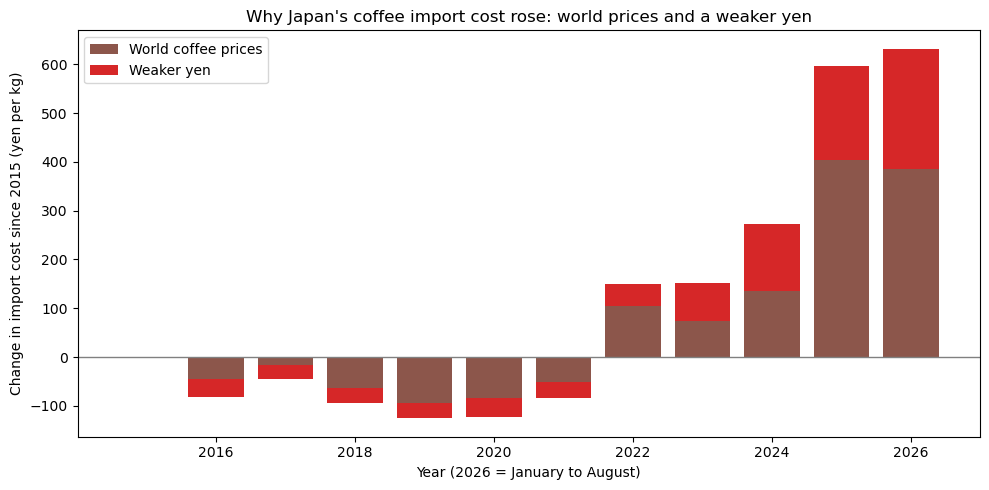

In [19]:
# Stacked bars: each bar is the total increase since 2015, split into its two causes
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly.index, yearly["coffee_market_effect"], label="World coffee prices", color="tab:brown")
ax.bar(yearly.index, yearly["weak_yen_effect"], bottom=yearly["coffee_market_effect"],
       label="Weaker yen", color="tab:red")

# Line at zero (the 2015 level)
ax.axhline(0, color="gray", linewidth=1)

# Labels and title
ax.set_title("Why Japan's coffee import cost rose: world prices and a weaker yen")
ax.set_ylabel("Change in import cost since 2015 (yen per kg)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# ---------- Japan Consumer Price Index (CPI) for coffee ----------
# Source: Statistics Bureau of Japan, 2025-base CPI, all Japan, monthly (via e-Stat)
# Values are an index (2025 average = 100), not yen
cpi = pd.read_csv(DATA + r"\japan_coffee_cpi_2010_2026.csv")

# Convert "2010-01" text into real dates
cpi["month"] = pd.to_datetime(cpi["month"])

# Health check: size, missing values per column, date range
print("CPI")
print("Shape:", cpi.shape)
print(cpi.isna().sum())
print("Dates:", cpi["month"].min().date(), "to", cpi["month"].max().date())

CPI
Shape: (200, 9)
month                            0
cpi_all_items                    0
cpi_coffee_and_cocoa             0
cpi_instant_coffee               0
cpi_coffee_beans                 0
cpi_coffee_beverage_A            0
cpi_coffee_beverage_B           60
cpi_cafe_coffee_coffee_shop      0
cpi_cafe_coffee_self_service    60
dtype: int64
Dates: 2010-01-01 to 2026-08-01


In [21]:
# Columns to compare: overall inflation, store-bought coffee, and cafe coffee
cpi_cols = ["cpi_all_items", "cpi_coffee_beans", "cpi_instant_coffee", "cpi_cafe_coffee_coffee_shop"]

# Yearly averages for the CPI columns
cpi["year"] = cpi["month"].dt.year
cpi_yearly = cpi.groupby("year")[cpi_cols].mean()

# Add Japan's yearly import cost from the Step 11 table
cpi_yearly["import_cost"] = yearly["import_yen_kg"]

# Keep 2015 onward and rescale every column so 2015 = 100
cpi_yearly = cpi_yearly.loc[2015:]
cpi_index = cpi_yearly / cpi_yearly.loc[2015] * 100

cpi_index.round(0)

,cpi_all_items,cpi_coffee_beans,cpi_instant_coffee,cpi_cafe_coffee_coffee_shop,import_cost
year,,,,,
2015,100.0,100.0,100.0,100.0,100.0
2016,100.0,99.0,104.0,100.0,80.0
2017,100.0,96.0,105.0,101.0,89.0
2018,101.0,93.0,110.0,101.0,77.0
2019,102.0,92.0,112.0,103.0,69.0
2020,102.0,92.0,108.0,105.0,70.0
2021,102.0,97.0,107.0,106.0,79.0
2022,104.0,113.0,117.0,109.0,136.0
2023,108.0,126.0,122.0,113.0,137.0


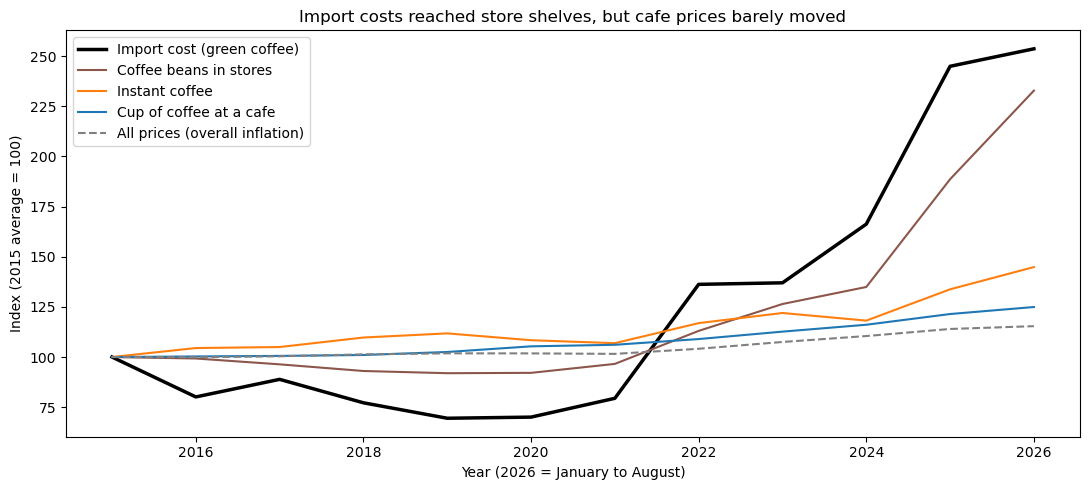

In [22]:
# One line per series, all indexed to 2015 = 100
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(cpi_index.index, cpi_index["import_cost"], label="Import cost (green coffee)", color="black", linewidth=2.5)
ax.plot(cpi_index.index, cpi_index["cpi_coffee_beans"], label="Coffee beans in stores", color="tab:brown")
ax.plot(cpi_index.index, cpi_index["cpi_instant_coffee"], label="Instant coffee", color="tab:orange")
ax.plot(cpi_index.index, cpi_index["cpi_cafe_coffee_coffee_shop"], label="Cup of coffee at a cafe", color="tab:blue")
ax.plot(cpi_index.index, cpi_index["cpi_all_items"], label="All prices (overall inflation)", color="gray", linestyle="--")

# Labels and title
ax.set_title("Import costs reached store shelves, but cafe prices barely moved")
ax.set_ylabel("Index (2015 average = 100)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# ---------- Store and cafe prices by city ----------
# Source: Statistics Bureau of Japan, Retail Price Survey, prices by city (via e-Stat)
# Prices are in yen. Item codes: 1921 instant coffee, 1922 ground coffee (per 100g),
# 2162 cafe coffee at a coffee shop (per cup), 2165 self-service cafe coffee (per cup)
city = pd.read_csv(DATA + r"\japan_coffee_retail_prices_by_city_2010_2026.csv")

# Convert "2010-01" text into real dates, and add a year column
city["month"] = pd.to_datetime(city["month"])
city["year"] = city["month"].dt.year

# Health check
print("CITY PRICES")
print("Shape:", city.shape)
print("Cities:", city["city"].unique())
print("Items:", city["item"].unique())
print("Missing prices:", city["price_yen"].isna().sum())

city.head()

CITY PRICES
Shape: (2960, 7)
Cities: ['Kyoto' 'Naha' 'Sapporo' 'Tokyo (23 wards)']
Items: ['Instant coffee' 'Ground coffee (regular coffee)'
 'Cafe coffee, coffee shop' 'Cafe coffee, self-service chain']
Missing prices: 2


,month,city,item_code,item,unit,price_yen,year
0,2010-01-01,Kyoto,1921,Instant coffee,per 100g,665.0,2010
1,2010-02-01,Kyoto,1921,Instant coffee,per 100g,703.0,2010
2,2010-03-01,Kyoto,1921,Instant coffee,per 100g,673.0,2010
3,2010-04-01,Kyoto,1921,Instant coffee,per 100g,703.0,2010
4,2010-05-01,Kyoto,1921,Instant coffee,per 100g,703.0,2010


In [24]:
# Keep only cafe coffee at a coffee shop (item 2162)
cafe = city[city["item_code"] == 2162]

# pivot_table: rows = years, columns = cities, values = average price that year
cafe_yearly = cafe.pivot_table(index="year", columns="city", values="price_yen", aggfunc="mean")

# Keep 2015 onward to match the rest of the project
cafe_yearly = cafe_yearly.loc[2015:]

# Price in yen, and the same prices indexed to 2015 = 100
print("Price of a cup of coffee (yen):")
print(cafe_yearly.round(0))
print()
print("Index (2015 = 100):")
print((cafe_yearly / cafe_yearly.loc[2015] * 100).round(0))

Price of a cup of coffee (yen):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  414.0  365.0    420.0             422.0
2016  415.0  378.0    420.0             434.0
2017  415.0  379.0    420.0             450.0
2018  418.0  381.0    420.0             479.0
2019  423.0  396.0    430.0             491.0
2020  442.0  403.0    449.0             512.0
2021  448.0  375.0    447.0             513.0
2022  466.0  377.0    452.0             520.0
2023  493.0  401.0    473.0             547.0
2024  542.0  390.0    492.0             571.0
2025  566.0  411.0    536.0             613.0
2026  597.0  434.0    558.0             629.0

Index (2015 = 100):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  100.0  100.0    100.0             100.0
2016  100.0  104.0    100.0             103.0
2017  100.0  104.0    100.0             107.0
2018  101.0  105.0    100.0             114.0
2019  102.0  109.0    102.0

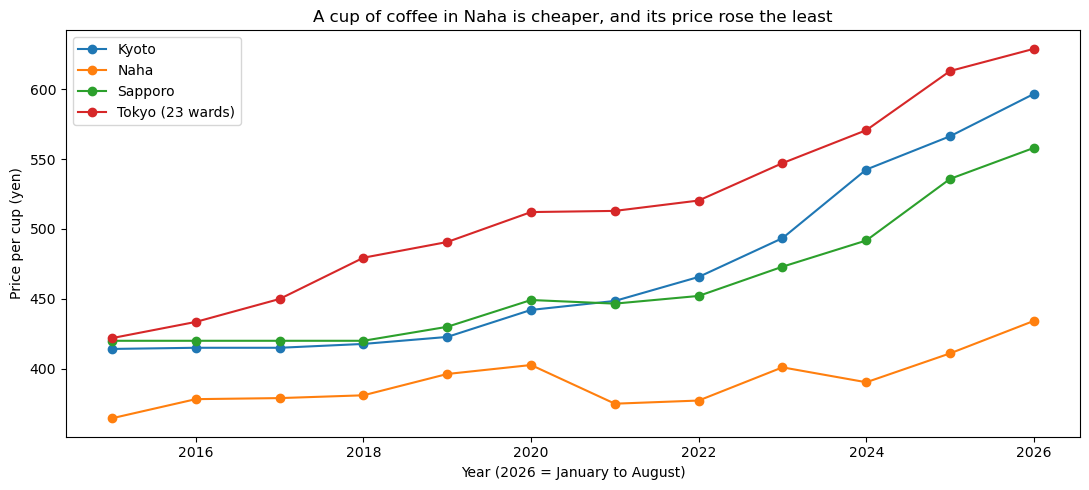

In [25]:
# One line per city: price of a cup of coffee at a coffee shop
fig, ax = plt.subplots(figsize=(11, 5))
for c in cafe_yearly.columns:
    ax.plot(cafe_yearly.index, cafe_yearly[c], label=c, marker="o")

# Labels and title
ax.set_title("A cup of coffee in Naha is cheaper, and its price rose the least")
ax.set_ylabel("Price per cup (yen)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

Price of ground coffee (yen per 100g):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  144.0  161.0    139.0             150.0
2016  138.0  153.0    144.0             149.0
2017  132.0  134.0    133.0             147.0
2018  133.0  137.0    133.0             141.0
2019  131.0  152.0    136.0             137.0
2020  129.0  150.0    132.0             136.0
2021  139.0  153.0    138.0             140.0
2022  157.0  162.0    162.0             160.0
2023  174.0  191.0    184.0             177.0
2024  195.0  191.0    197.0             189.0
2025  254.0  270.0    267.0             266.0
2026  334.0  331.0    346.0             339.0

Index (2015 = 100):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  100.0  100.0    100.0             100.0
2016   96.0   95.0    103.0              99.0
2017   92.0   83.0     95.0              98.0
2018   93.0   86.0     96.0              94.0
2019   91.0   94.0  

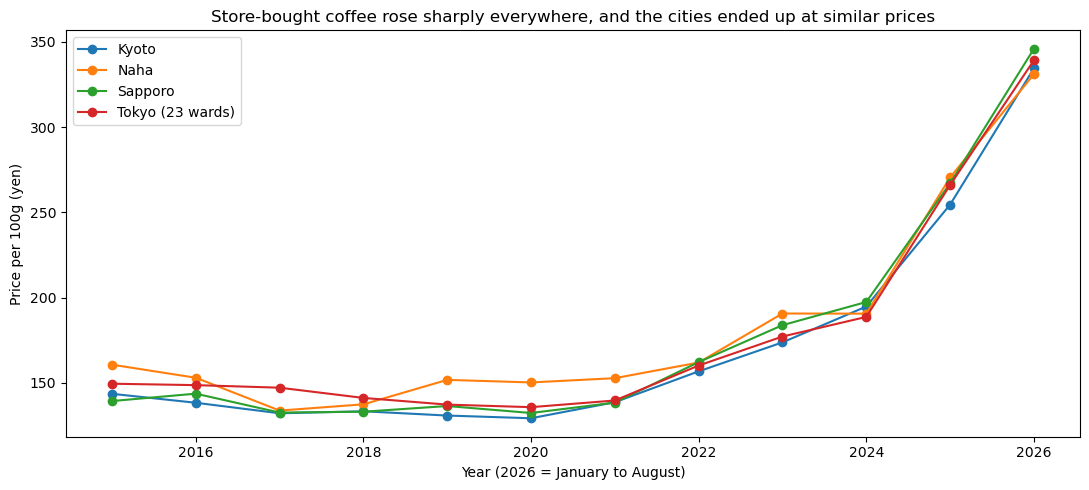

In [26]:
# ---------- Step 13d: Store-bought ground coffee by city ----------
# Item 1922: regular ground coffee in a bag, price per 100g
# Note: the surveyed bag size shrank over time (450-500g in 2010, 200-260g by 2026),
# so part of the per-100g increase is smaller bags ("shrinkflation"), not just coffee costs

# Keep only ground coffee (item 1922)
beans = city[city["item_code"] == 1922]

# Rows = years, columns = cities, values = average price that year
beans_yearly = beans.pivot_table(index="year", columns="city", values="price_yen", aggfunc="mean")
beans_yearly = beans_yearly.loc[2015:]

# Price in yen, and the same prices indexed to 2015 = 100
print("Price of ground coffee (yen per 100g):")
print(beans_yearly.round(0))
print()
print("Index (2015 = 100):")
print((beans_yearly / beans_yearly.loc[2015] * 100).round(0))

# Chart: one line per city
fig, ax = plt.subplots(figsize=(11, 5))
for c in beans_yearly.columns:
    ax.plot(beans_yearly.index, beans_yearly[c], label=c, marker="o")

ax.set_title("Store-bought coffee rose sharply everywhere, and the cities ended up at similar prices")
ax.set_ylabel("Price per 100g (yen)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()